# Client and segmenter as separate processes, with delay

In the baselines a segmentation result was available on the same frame it was computed for. Here I separate the client and the segmenter into two processes and add a delay, so the mask arrives when the client is already some frames further.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

import client
import pipeline as p

RESULTS_PATH = "results/delay_frames.csv"
RUN_SWEEP = False  # the sweep replays all sequences in real time and takes about 70 minutes

## How it works

The segmenter (`segmenter.py`) holds the YOLO model. It receives a frame over a local socket and sends back the combined mask.

The client (`client.py`) replays the frames at 10 fps. It sends every 5th frame to the segmenter as a JPEG and does not wait for the answer. In between it keeps a mask by itself, either by holding the last one or by moving it with optical flow.

A mask becomes usable a fixed time after its request was sent, this is the delay I control. With a delay of 0 only the real time of the two processes counts. Both processes run on my laptop, so the real network time is close to zero.

When a mask becomes usable it describes an old frame. With holding it is used as it is. With flow the client first moves it over the frames that passed since, with the flows it has already computed for these frames.

I run this on the 12 development sequences for delays of 0, 150, 350 and 550 ms.

In [2]:
if RUN_SWEEP:
    client.main()

results = pd.read_csv(RESULTS_PATH, dtype={"seq": str})

## Results

The mask age is the number of frames between the frame a mask was segmented from and the frame it is used on. The latency is the time from sending a request until its mask is used. The traffic is counted from the bytes sent over the socket.

In [3]:
summary = results.groupby(["method", "delay_ms"], sort=False).apply(client.summarize, include_groups=False)
summary[["iou", "mask_age", "latency_ms"]].round(3)

iou  mask_age  latency_ms
method delay_ms                             
hold   0         0.534     2.998      99.357
       150       0.477     3.996     198.906
       350       0.410     5.999     399.153
       550       0.373     7.994     598.801
flow   0         0.809     3.001     113.160
       150       0.780     3.996     212.547
       350       0.728     5.994     413.028
       550       0.683     7.994     612.043

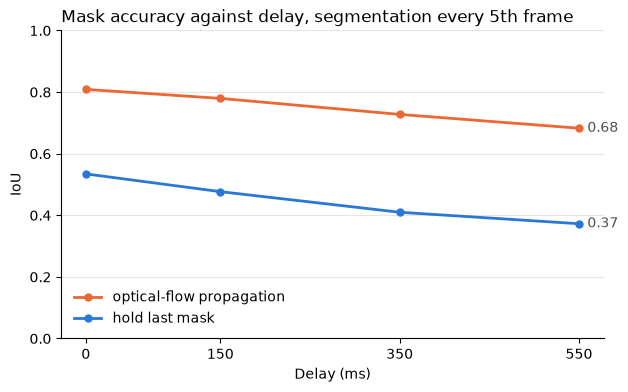

In [4]:
LABELS = {"hold": "hold last mask", "flow": "optical-flow propagation"}
COLOURS = {"hold": "#2a78d6", "flow": "#eb6834"}

fig, ax = plt.subplots(figsize=(7, 4))
for method in ["flow", "hold"]:
    s = summary.loc[method, "iou"]
    ax.plot(s.index, s.values, color=COLOURS[method], linewidth=2, marker="o", markersize=5, label=LABELS[method])
    ax.annotate(f"{s.values[-1]:.2f}", (s.index[-1], s.values[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color="#52514e")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e6e5e1", linewidth=0.8)
ax.set_axisbelow(True)
ax.set_xticks(s.index)
ax.set_xlabel("Delay (ms)")
ax.set_ylabel("IoU")
ax.set_ylim(0, 1)
ax.set_title("Mask accuracy against delay, segmentation every 5th frame", loc="left")
ax.legend(frameon=False, loc="lower left");

Already without added delay the IoU is lower than in the baselines, 0.81 instead of 0.84 for flow and 0.53 instead of 0.62 for holding. The client does not wait, so it can use an answer on the next frame at the earliest and the freshest mask is always one frame old. The frames are also sent as JPEG and a little bit compressed, which the baselines did not do.

With more delay holding gets worse quickly, down to 0.37 at 550 ms. Flow loses less, it is still at 0.68 at 550 ms.

The mean mask age grows by one frame for every 100 ms of delay, from 3 frames without delay to 8 frames at 550 ms.

## Accuracy against mask age

The delay hurts because it makes the mask older, so I also look at the IoU for each mask age. I pool the four delays, because every delay reaches only some of the ages.

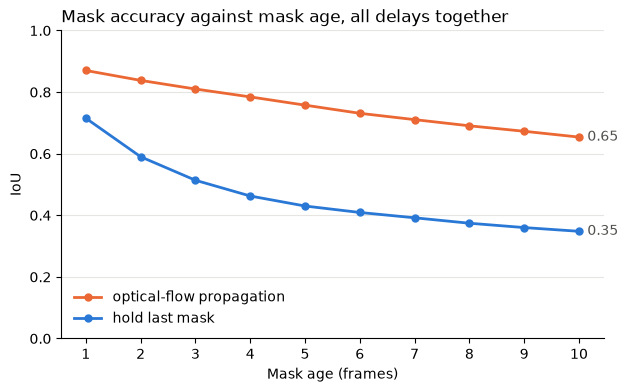

In [5]:
by_age = results.groupby(["method", "mask_age"])[["intersection", "union"]].sum()
by_age["iou"] = by_age["intersection"] / by_age["union"]

fig, ax = plt.subplots(figsize=(7, 4))
for method in ["flow", "hold"]:
    s = by_age.loc[method, "iou"]
    ax.plot(s.index, s.values, color=COLOURS[method], linewidth=2, marker="o", markersize=5, label=LABELS[method])
    ax.annotate(f"{s.values[-1]:.2f}", (s.index[-1], s.values[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color="#52514e")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e6e5e1", linewidth=0.8)
ax.set_axisbelow(True)
ax.set_xticks(s.index.astype(int))
ax.set_xlabel("Mask age (frames)")
ax.set_ylabel("IoU")
ax.set_ylim(0, 1)
ax.set_title("Mask accuracy against mask age, all delays together", loc="left")
ax.legend(frameon=False, loc="lower left");

Holding loses most of its accuracy in the first frames, from 0.72 at age 1 to 0.51 at age 3 and 0.35 at age 10. Flow starts higher, at 0.87 for age 1, and falls much more slowly, to 0.65 at age 10. From age 3 on it stays about 0.3 above holding.

Looked at for each delay separately, the IoU is almost the same at the same age, except for a few ages that occur only a handful of times in a run. So it is the age of the mask, not the delay itself, that costs accuracy. The delay matters because it makes the masks older.

## Traffic and client time

In [6]:
summary[["requests", "up_kbit_s", "down_kbit_s", "client_ms", "late"]].round(3)

requests  up_kbit_s  down_kbit_s  client_ms  late
method delay_ms                                                   
hold   0           1010.0   2090.514       18.436      0.512   0.0
       150         1010.0   2090.514       18.436      0.510   0.0
       350         1010.0   2090.514       18.436      0.512   0.0
       550         1010.0   2090.514       18.436      0.504   0.0
flow   0           1010.0   2090.514       18.436     17.276   0.0
       150         1010.0   2090.514       18.436     18.217   0.0
       350         1010.0   2090.514       18.436     19.558   0.0
       550         1010.0   2090.514       18.436     19.647   0.0

The number of requests is the same in every run (1,010), so the traffic does not depend on the delay. Sending the frames takes about 2.1 Mbit/s and the masks coming back only about 18 kbit/s.

The client needs about 0.5 ms per frame with holding and about 20 ms with flow. With flow it grows a little with the delay, from 17 to 20 ms, because an older mask has to be moved over more frames. No frame took longer than the 100 ms frame period.